# Data Science 3160 project: By Benjamin Hogg & Elijah Stolte
## [Website Link](https://elistolte.github.io)

### Project Goals

Our names are Benjamin Hogg and Elijah Stolte, and we are planning on studying datasets related to food recalls in the United States. We have found two datasets which we have done our initial EDA on. One is a dataset of current food recalls in the US and the second is an FDA dataset of recalls in the US beginning in 2004 (though the data really only includes relevant information from 2013 to now). We plan to explore the trends among the types of recalls most prevelent now and compare them to trends over time. In the future, we might also try to incorporate data of foodborne illness or data surrounding any of the specific trends in kinds of food recalls such as an increase in beef recalls and why this might have been ocurring.


### Collaboration Plan
For our project, we have created a github repository in which we are both collaborators and will store our project. Within our github repository we will maintain a text file with a to-do list and work division and allocation. We have also exchanged contact information and are planning to meet weekly moving forward to work on the tutorial and stay afloat of project deadlines.

There are a few possible datasets that we want to work with, after some investigation into the links provided on the github page for the project. Two related datasets that stood out to us were the following:
1. https://dailyfoodrecalls.com/api/recalls.json
    - This is a dataset that lists every current food recall active in the United States. This is interesting due to the current relevance that food recalls have on our public, most notably with the beef recall happening due to lax foreign import rules.
    - A question that we might want answered from this data set is, "Which recalls are getting more frequent, or which recalls are just a few events (Beef (ongoing), Salmonella (spike))." We could also explore the question, "How exposed is Louisiana to food recalls as of now?"
2. https://open.fda.gov/apis/food/enforcement/
    - This dataset from the FDA reports data from their Recall Enterprise System which contains information on recall events from 2004 to present.
    - Some of this data is similar to the above data but as a historical database, can allow us to answer questions about historical trends such as, "Have beef recalls increased over the past 20 years?"

In [ ]:
from google.colab import userdata
import zipfile
import pandas as pd, requests
import numpy as np
import json
import matplotlib.pyplot as plt

%cd /content
!git clone https://github.com/elistolte/elistolte.github.io.git
%cd /content/elistolte.github.io

#Getting the second dataset from the github repository.
with zipfile.ZipFile("food_recall.zip", "r") as z:
    with z.open("food-enforcement-0001-of-0001.json") as f:
        fda_data = json.load(f)
fda_hist = pd.json_normalize(fda_data["results"])

/content
fatal: destination path 'elistolte.github.io' already exists and is not an empty directory.
/content/elistolte.github.io


## Data Source 1

The data comes from the [Daily Food Recalls API](https://dailyfoodrecalls.com/api/recalls.json), a free public JSON feed of every food recall currently active in the US.

In [ ]:
recalls = pd.json_normalize(requests.get("https://dailyfoodrecalls.com/api/recalls.json").json()["recalls"])

Show our data shape to see where we need to go from here

In [ ]:
print(recalls.shape)
recalls.head()

(356, 35)


,id,product,brand,company,category,class,classInferred,agency,hazard,hazardType,...,reasonField,score,breaking,firstSeen,slug,state,url,productItems,sources,mergedIds
0,fda-rss-krasnyi-oktyabr-inc-recalls-starfish-s...,Starfish Seafood Trio Because of Possible Heal...,Krasnyi Oktyabr Inc.,Krasnyi Oktyabr Inc.,Food,1,True,FDA,Listeria monocytogenes,pathogen,...,Potential to be contaminated with Listeria mon...,95,True,2026-10-09T21:17:06.681Z,krasnyi-oktyabr-inc-starfish-seafood-trio-beca...,active,https://dailyfoodrecalls.com/recall/krasnyi-ok...,NaN,NaN,NaN
1,fda-rss-gardeners-basics-recalls-waltham-29-br...,Waltham 29 Broccoli Sprouting Seeds Due to Pos...,Gardeners Basics,Gardeners Basics,Food,1,True,FDA,Salmonella,pathogen,...,Product may be contaminated with Salmonella,105,True,2026-10-09T02:47:05.212Z,gardeners-basics-waltham-29-broccoli-sprouting...,active,https://dailyfoodrecalls.com/recall/gardeners-...,NaN,NaN,NaN
2,fda-rss-eden-brothers-recalls-calabrese-brocco...,Calabrese Broccoli Seeds Due to Possible Salmo...,Eden Brothers,Eden Brothers,Food,1,True,FDA,Salmonella,pathogen,...,Potential to be contaminated with Salmonella,105,True,2026-10-08T04:01:51.256Z,eden-brothers-calabrese-broccoli-seeds-due-to-...,active,https://dailyfoodrecalls.com/recall/eden-broth...,NaN,NaN,NaN
3,usda-025-2026,Ineligible Pork Cracklings Products,Inexport Logistics LLC,Inexport Logistics LLC,Meat & Poultry,1,NaN,USDA,Not federally inspected,labeling,...,NaN,72,False,2026-10-03T15:30:05.752Z,inexport-logistics-llc-ineligible-pork-crackli...,active,https://dailyfoodrecalls.com/recall/inexport-l...,[60-g. foil bags of “YUPI GOLPE CON TODO SABOR...,NaN,NaN
4,fda-rss-eak-distribution-llc-recalls-home-grow...,HOME GROWN Green Sprouting Calabrese Broccoli ...,EAK Distribution LLC,EAK Distribution LLC,Food,1,True,FDA,Salmonella,pathogen,...,Potential to be contaminated with Salmonella,105,True,2026-10-03T00:14:33.994Z,eak-distribution-llc-home-grown-green-sproutin...,active,https://dailyfoodrecalls.com/recall/eak-distri...,NaN,NaN,NaN


The raw data has 356 recalls and 35 columns. Many of these are metadata (URL's, internal scores) that don't do anything for us.

We decided to only keep the columns for:
- product & company (who made it and what is it)
- which agency (FDA or USDA)
- class (how bad the health consequences are)
- classInferred (if the website guessed or got it straight from the agency)
- hazard (what the actual problem is)
- allergens (allergens)
- affectedStates (which states the recall affects)
- recall type (voluntary or agency requested)
- recall initiated & report date (when the recall happened and when it was reported)

In [ ]:
# raw data has 35 columns, many are metadata. Only keep relevant
cols = ["product", "company", "agency", "class", "classInferred", "hazard", "hazardType", "allergens", "affectedStates", "recallType", "recallInitiated", "reportDate"]
recalls = recalls[cols].copy()

Here we fix the data types and missing values.

Many columns did not import correctly:
- dates came as plain strings and we need to convert them to datetime.
- class came in as a number but it's actually ordinal.
- hazardtype and agency only have a few possible values, so they become categorical.
- classInferred is only present when the website guessed the recall's class. We need to fill the gaps with False.
- hazard: This is incomplete information that isn't nan, sometimes just said 'see official notice' which is not helpful at all, need to NaN them


In [ ]:
# dates are strings
recalls["recallInitiated"] = pd.to_datetime(recalls["recallInitiated"])
recalls["reportDate"] = pd.to_datetime(recalls["reportDate"])

# class is an ordered severity ranking
recalls["class"] = pd.Categorical(recalls["class"], categories=[1, 2, 3], ordered=True)
recalls["hazardType"] = recalls["hazardType"].astype("category")
recalls["agency"] = recalls["agency"].astype("category")

# classInferred is only present when the site guessed the class
recalls["classInferred"] = recalls["classInferred"].fillna(False).astype(bool)

# placeholder hazards are missing values
recalls["hazard"] = recalls["hazard"].replace(["", "See official notice", "Possible contamination"], pd.NA)

/tmp/ipykernel_1464/2412042070.py:11: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  recalls["classInferred"] = recalls["classInferred"].fillna(False).astype(bool)


Check our dtypes to make sure we did it correctly.

In [ ]:
# check our dtypes
recalls.dtypes

,0
product,object
company,object
agency,category
class,category
classInferred,bool
hazard,object
hazardType,category
allergens,object
affectedStates,object
recallType,object


Check which columns have missing values, should only be hazard which we had to manually replace (classInferred was given falses not nans).

In [ ]:
recalls.isna().sum()

,0
product,0
company,0
agency,0
class,0
classInferred,0
hazard,60
hazardType,0
allergens,0
affectedStates,0
recallType,0


Challenges we faced:
- Nested JSON: the data was a json object with metadata around it. Had to pull out the json and flatten it.
- Vague placeholder columns: Didn't figure this out until inspecting the data manually, 60 hazard columns had vague information like 'see official notice' instead of a real hazard, and didn't show up as NaN.
- Inferred values: A lot of recalls had a severity class that was inferred instead of given to them by the FDA/USDA.
- Live data, this is just a snapshot instead of a fixed dataset (no historical data either).

## Data Analysis 1

How severe are current recalls?

208 of the 356 active recalls are Class I, the most dangerous class. Only 19 are Class III. Most recalls currently in effect are serious ones.


In [ ]:
# number of recalls in each severity class (1 = most severe)
severity = recalls.groupby("class", observed=True).agg(count=("product", "size"),inferred=("classInferred", "sum"))
severity["percent"] = (severity["count"] / severity["count"].sum() * 100).round(1)
print(severity)

       count  inferred  percent
class                          
1        208        35     58.4
2        129        53     36.2
3         19         1      5.3


Does type of hazard determine severity?

Almost every pathogen recall (167 of 181) is Class I, while allergen recalls are mostly Class II (66 of 109) and foreign-material recalls are all Class II. The type of hazard largely determines how dangerous a recall is.

In [ ]:
# hazard type vs. severity class: count of recalls in each combination
hazard_by_class = recalls.pivot_table(index="hazardType", columns="class", values="product", aggfunc="count", fill_value=0, observed=True)
hazard_by_class

class,1,2,3
hazardType,,,
allergen,33,66,10
chemical,3,18,7
foreign-material,0,25,0
labeling,5,7,1
pathogen,167,13,1


What are the most common hazards?

Salmonella and listeria show up most often. Undeclared allergens are spread across a bunch of different combinations of foods so it doesn't show up near the top.

In [ ]:
# five most common specific hazards
top_hazards = recalls.groupby("hazard").agg(count=("product", "size")).sort_values("count", ascending=False).head(5)
top_hazards

,count
hazard,
Salmonella,100
Listeria monocytogenes,38
Foreign material,25
"Undeclared milk, tree nuts",18
Undeclared color additive,14


Graph of hazard type by severity class:


Displaying a bar chart to display which hazards correspond to which class. Shows that pathogen related recalls are almost entirely class I while others are mostly class II.

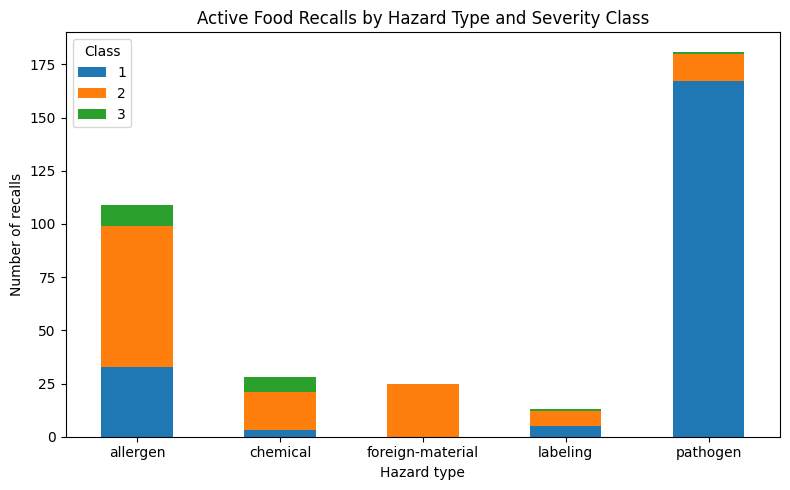

In [ ]:
ax = hazard_by_class.plot(kind="bar", stacked=True, figsize=(8, 5))
ax.set_title("Active Food Recalls by Hazard Type and Severity Class")
ax.set_xlabel("Hazard type")
ax.set_ylabel("Number of recalls")
ax.legend(title="Class")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Data Source 2

This is the data from the FDA RES (https://open.fda.gov/apis/food/enforcement/) summarizing recall data over time since 2004.

In [ ]:
fda_hist.head()

,status,city,state,country,classification,product_type,event_id,recalling_firm,address_1,address_2,...,recall_number,product_description,product_quantity,reason_for_recall,recall_initiation_date,center_classification_date,report_date,code_info,more_code_info,termination_date
0,Ongoing,San Francisco,CA,United States,Class III,Food,99859,"Kwok Shing, Inc.",1150 Thomas Ave,,...,H-1393-2026,American Ginsengs. PRODUCT OF WISCONSIN. NET W...,70 boxes,Potential contamination with pesticides.,20260908,20260922,20260930,108-728-420,,NaN
1,Ongoing,New York,NY,United States,Class I,Food,99853,GIAS FOOD INC.,360 Madison Ave Fl 7,,...,H-1396-2026,Lemon Alfredo Fettuccine packed in a yellow pl...,"16,002 bags (2,286 cases)",Contamination with Listeria monocytogenes,20260903,20260924,20260930,L6080C SEP 20 2027 L6079C SEP 19 2027,,NaN
2,Ongoing,Austin,TX,United States,Class I,Food,99874,"WFM Purchasing, LP",550 Bowie St,,...,H-1395-2026,Fromagerie Coop de Mean Cabricharme and Belgiu...,21 Wheels,Undeclared Egg Allergen,20260908,20260922,20260930,"Shelf life: 30 days, all dates through and inc...",,NaN
3,Ongoing,Englewood Cliffs,NJ,United States,Not Yet Classified,Food,99757,"Unilever North America Supply Chain Company, LLC",700 Sylvan Ave,,...,,"Almond Joy Ice Cream Bar, 2.0 fl. oz. ice cre...","63,226 cases",Inaccurate Nutrition Facts information listed ...,20260811,NaN,20260930,APR0927XS3 APR1027XS3 JUN1527XS3 JUN1627XS3 AU...,,NaN
4,Ongoing,Minneapolis,MN,United States,Class II,Food,99717,United Sugar Producers and Refiners,8000 W 78th St Ste 300,,...,H-1391-2026,"Light Brown Sugar, Packaged in he follow confi...","12,678 CWT total",Potential Wheat Kernel contamination.,20260819,20260921,20260930,"1. Batch Numbers: MHD26223, MHD26224, MHD262...",,NaN


In [ ]:
# Lists all of the columns in the dataset.
print(fda_hist.columns.tolist())
# Fix the date variables so they are in date format instead of a string of numbers.
for col in ["recall_initiation_date", "center_classification_date", "report_date"]:
  fda_hist[col] = pd.to_datetime(
      fda_hist[col].astype("string").str.strip(),
      format = "%Y%m%d",
      errors = "coerce"
  )
  print(fda_hist["recall_initiation_date"])
# Some entries are missing the state.
fda_hist["state"] = fda_hist["state"].replace(r"^\s*$", np.nan, regex = True).fillna("Unknown")

['status', 'city', 'state', 'country', 'classification', 'product_type', 'event_id', 'recalling_firm', 'address_1', 'address_2', 'postal_code', 'voluntary_mandated', 'initial_firm_notification', 'distribution_pattern', 'recall_number', 'product_description', 'product_quantity', 'reason_for_recall', 'recall_initiation_date', 'center_classification_date', 'report_date', 'code_info', 'more_code_info', 'termination_date']
0       2026-09-08
1       2026-09-03
2       2026-09-08
3       2026-08-11
4       2026-08-19
           ...    
29466   2016-10-12
29467   2026-03-05
29468   2025-11-22
29469   2024-11-29
29470   2024-11-29
Name: recall_initiation_date, Length: 29471, dtype: datetime64[ns]
0       2026-09-08
1       2026-09-03
2       2026-09-08
3       2026-08-11
4       2026-08-19
           ...    
29466   2016-10-12
29467   2026-03-05
29468   2025-11-22
29469   2024-11-29
29470   2024-11-29
Name: recall_initiation_date, Length: 29471, dtype: datetime64[ns]
0       2026-09-08
1      

There were similar challenges faced with this data set compared to the last one such as the format of the dates. The information was also in a json within a zip file which was a little bit challenging to figure out how to get into the notebook without requiring a local download.

The various fields for each entry within this dataset are described [here](https://open.fda.gov/apis/food/enforcement/searchable-fields/).


## Data Analysis 2

This dataset includes geographic information so we can compare recalls from multiple states.

Here we ranked the states with the most recalls in 2020.

In [ ]:
# Creates a dataframe that displays the states in order of the most number of recalls in 2020.
data_2020 = fda_hist[fda_hist["recall_initiation_date"].dt.year == 2020].groupby("state").size().reset_index(name = "Number of Recalls").sort_values("Number of Recalls", ascending = False).reset_index(drop=True)
data_2020

,state,Number of Recalls
0,NY,174
1,FL,124
2,CA,117
3,TX,109
4,WA,107
5,PA,67
6,MI,56
7,OH,46
8,UT,40
9,OR,35


The biggest difference and point of including this dataset is the ability it gives us to look at the recalls relative to time. Here we compare the number of recalls per year.

In [75]:
year_ranking = fda_hist["recall_initiation_date"].dt.year.astype("Int64").value_counts().rename_axis("Year").reset_index(name = "Number of Recalls").sort_values("Number of Recalls", ascending = False).reset_index(drop = True)
print(fda_hist["recall_initiation_date"].min())
year_ranking

2008-02-22 00:00:00


,Year,Number of Recalls
0,2016,3066
1,2015,2750
2,2017,2623
3,2014,2451
4,2013,2420
5,2023,2221
6,2012,2151
7,2018,1977
8,2019,1807
9,2025,1571


Evidently, the dates only really go back to 2008 here even though the API claims that they go back to 2004. That being said, it might be best to only consider years with significant data on recalls such as 2013 to 2026.

One more interesting stat that we can glean from this is is an average wait time from recall initiation to the time the FDA issues an enforcement report.

In [86]:
fda_hist["report_delay"] = (fda_hist["report_date"] - fda_hist["recall_initiation_date"]).dt.days
print("Average Delay from Recall Initiation to Report:", fda_hist["report_delay"].mean(), "days")

Average Delay from Recall Initiation to Report: 72.377536477774 days


Finally, we can create graphs like this one to display the number of recalls in an area over time.

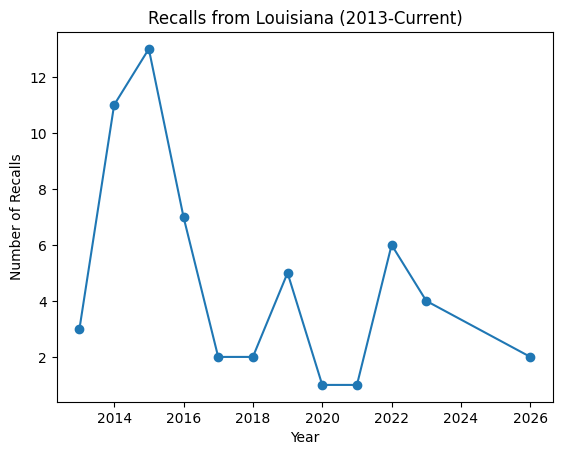

In [85]:
Lrecalls = fda_hist[(fda_hist["state"] == "LA") & fda_hist["recall_initiation_date"].dt.year.between(2013, 2027)].groupby(fda_hist["recall_initiation_date"].dt.year).size()
Lrecalls.index = Lrecalls.index.astype(int)
Lrecalls.plot(kind = "line", marker = "o")
plt.xlabel("Year")
plt.ylabel("Number of Recalls")
plt.title("Recalls from Louisiana (2013-Current)")
plt.show()

### Next steps

For our next steps, we will determine what additional datasets we would like to incorporate into the tutorial such as potentially another one from the FDA including adverse events related to food recalls. We will also continue to analyze the data from the two datasets that we have by improving visualizations and better understanding the trends present within the datasets.

### Export to website

Save the notebook first, then run this cell to export it to `index.html` for our GitHub Pages site.

In [ ]:
# export the saved notebook to index.html (sys.executable makes it use this notebook's Python environment)
import sys
!{sys.executable} -m jupyter nbconvert --to html notebook.ipynb --output index

[NbConvertApp] Converting notebook notebook.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 1 image(s).
[NbConvertApp] Writing 360497 bytes to index.html
